In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Basis states and the Hadamard gate

ket0 = np.array([1, 0], dtype=complex)  # |0⟩
ket1 = np.array([0, 1], dtype=complex)  # |1⟩

H = np.array([[1,  1],
              [1, -1]], dtype=complex) / np.sqrt(2)

In [3]:
# Superposition and measurement

plus = H @ ket0

print("state:", np.round(plus, 3))
print("P(0), P(1):", np.round(np.abs(plus)**2, 3))

state: [0.707+0.j 0.707+0.j]
P(0), P(1): [0.5 0.5]

In [4]:
# Two qubits and entanglement

ket00 = np.kron(ket0, ket0)   # |00⟩ = |0⟩ ⊗ |0⟩

I = np.eye(2, dtype=complex)

CNOT = np.array([[1, 0, 0, 0],
                 [0, 1, 0, 0],
                 [0, 0, 0, 1],
                 [0, 0, 1, 0]], dtype=complex)

bell = CNOT @ np.kron(H, I) @ ket00   # first H on qubit 0, then CNOT

print("state:", np.round(bell, 3))
print("P(00), P(01), P(10), P(11):", np.round(np.abs(bell)**2, 3))

state: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
P(00), P(01), P(10), P(11): [0.5 0.  0.  0.5]

In [5]:
# Shots: what it looks like in practice

rng = np.random.default_rng(42)
probs = np.abs(bell)**2
outcomes = rng.choice(["00", "01", "10", "11"], size=1000, p=probs)
labels, counts = np.unique(outcomes, return_counts=True)
print(dict(zip(labels, counts)))

{np.str_('00'): np.int64(503), np.str_('11'): np.int64(497)}

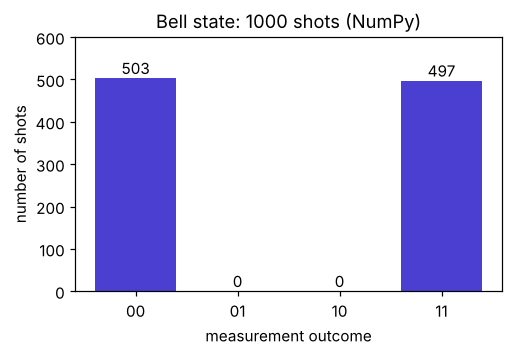

In [6]:
all_outcomes = ["00", "01", "10", "11"]
tally = {w: int(np.sum(outcomes == w)) for w in all_outcomes}

plt.figure(figsize=(5, 3))
plt.bar(tally.keys(), tally.values(), color="#4b3fd1")
plt.xlabel("measurement outcome")
plt.ylabel("number of shots")
plt.title("Bell state: 1000 shots (NumPy)")
for w, n in tally.items():
    plt.text(w, n + 10, n, ha="center")
plt.ylim(0, 600)
plt.show()